# EMQA_L5_case2026

**Case study 2026: cost of four hedging strategies**

Energy Markets Quantitative Analysis (EMQA), Lecture 5 · Daniel Traian Pele, Bucharest University of Economic Studies

[Open in Colab](https://colab.research.google.com/github/danpele/EMQA/blob/main/Quantlets/L5/EMQA_L5_case2026/EMQA_L5_case2026.ipynb)

In [1]:
import os
# course data: the local copy of the repository if there is one, else the public repository on GitHub
_LOCAL = os.path.join('..', '..', '..', 'data', 'clean')
DATA = _LOCAL + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/EMQA/main/data/clean/'
REPO = os.path.join('..', '..', '..') + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/EMQA/main/'

A supplier buys 1 MW of baseload for 2026: spot, forward, half and half, or monthly caps.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import warnings
warnings.filterwarnings('ignore')

# course chart style: transparent background, no gridlines, legend at the bottom outside the axes
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#222222', 'axes.labelcolor': '#222222', 'xtick.color': '#222222', 'ytick.color': '#222222',
    'text.color': '#222222', 'font.size': 11, 'axes.labelsize': 11, 'legend.fontsize': 10.5,
    'legend.frameon': False, 'lines.linewidth': 1.4, 'font.family': 'DejaVu Sans'})
# fixed colour per entity (course palette)
PAL = {'RO': '#2a78d6', 'DE_LU': '#eb6834', 'HU': '#1baf7a', 'BG': '#eda100',
       'c5': '#e87ba4', 'c6': '#008300', 'c7': '#6250d6', 'c8': '#e34948'}


def legend_bottom(fig, handles=None, labels=None, ncol=4):
    """Legend centred under the axes, outside the plotting area."""
    if handles is None:
        handles, labels = [], []
        for ax in fig.axes:
            for h, l in zip(*ax.get_legend_handles_labels()):
                if l not in labels:
                    handles.append(h)
                    labels.append(l)
    fig.legend(handles, labels, loc='lower center', ncol=ncol, bbox_to_anchor=(0.5, 0.0),
               frameon=False, handlelength=2.0, columnspacing=1.2)


def legend_compact(fig, ncol):
    """Bottom legend with shorter handles and column gaps, for many short entries."""
    legend_bottom(fig, ncol=ncol)
    h, l = fig.legends[-1].legend_handles, [t.get_text() for t in fig.legends[-1].get_texts()]
    fig.legends[-1].remove()
    fig.legend(h, l, loc='lower center', ncol=ncol, bbox_to_anchor=(0.5, 0.0), frameon=False,
               handlelength=1.0, handletextpad=0.4, columnspacing=0.9)


def save_chart(fig, name):
    """Keep under the axes exactly the height of the bottom legend, then save the PNG."""
    fig.canvas.draw()
    bottom = max([lg.get_window_extent().height / fig.bbox.height + 0.035 for lg in fig.legends] or [0.0])
    fig.tight_layout(rect=(0, bottom, 1, 1))
    plt.savefig(name + '.png', dpi=150, bbox_inches='tight', transparent=True)
    plt.show()


def show(label, value, key=None, fmt='.2f'):
    """Print one number of the slide; [key] = its name in lectures/L5/L5_numbers.json."""
    s = value if isinstance(value, str) else format(value, fmt)
    print(f'{label:<58s} {s:>12s}' + (f'   [{key}]' if key else ''))

In [3]:
# daily day-ahead base prices (mean of all market time units of the CET/CEST day), EUR/MWh
PD = pd.read_csv(DATA + 'power_da_prices_daily_cet.csv', parse_dates=['date_cet']).set_index('date_cet')
# cut-off = last complete month of the Romanian series
_last = PD['RO'].dropna().index.max()
END = pd.Timestamp(((_last + pd.Timedelta(days=1)).to_period('M').to_timestamp() - pd.Timedelta(days=1)).date())
d = lambda ts: pd.Timestamp(ts).strftime('%Y-%m-%d')
print('cut-off (last complete month):', d(END))

cut-off (last complete month): 2026-10-31


In [4]:
# OPCOM PCCB-LE-flex auction results: one row per traded session, price converted to EUR with the ECB EUR/RON fixing
FW = pd.read_csv(DATA + 'opcom_forward_trades.csv', parse_dates=['auction_date', 'delivery_start', 'delivery_end'])
FW = FW[FW['auction_date'] <= END].copy()


def kind_of(s, e):
    """Standard delivery period of a product: M (month), Q (quarter), H (half-year), Y (calendar year), else 'other'."""
    if s.day != 1 or (e + pd.Timedelta(days=1)).day != 1:
        return 'other'
    n = (e.year - s.year) * 12 + e.month - s.month + 1
    if n == 1:
        return 'M'
    if n == 3 and s.month in (1, 4, 7, 10):
        return 'Q'
    if n == 6 and s.month in (1, 7):
        return 'H'
    if n == 12 and s.month == 1:
        return 'Y'
    return 'other'


FW['kind'] = [kind_of(s, e) for s, e in zip(FW['delivery_start'], FW['delivery_end'])]
FW['lead_m'] = ((FW['delivery_start'].dt.year - FW['auction_date'].dt.year) * 12 +
                FW['delivery_start'].dt.month - FW['auction_date'].dt.month)
# baseload ('banda LD') products with a standard delivery period
BASE = FW[(FW['profile'] == 'banda LD') & (FW['kind'] != 'other')].copy()


def vwap(df):
    """Volume-weighted average price, EUR/MWh."""
    return float(np.average(df['price_eur_mwh'], weights=df['mwh'])) if len(df) else np.nan


def realised(s, e, col='RO'):
    """Mean day-ahead base price over [s, e] (CET days); NaN unless every day is present."""
    x = PD.loc[s:e, col]
    full = len(x) == (e - s).days + 1 and x.notna().all()
    return float(x.mean()) if full else np.nan


print(len(FW), 'traded auctions from', d(FW['auction_date'].min()), 'to', d(FW['auction_date'].max()),
      '|', len(BASE), 'baseload auctions with a standard delivery period')

2298 traded auctions from 2020-05-12 to 2026-10-28 | 1361 baseload auctions with a standard delivery period


In [5]:
# calendar-year baseload products
CY = BASE[BASE['kind'] == 'Y'].copy()
CY['dy'] = CY['delivery_start'].dt.year

In [6]:
def premium_table(base):
    """Ex-post forward premium of every baseload product fully delivered by the cut-off: F - realised mean spot."""
    b = base[base['delivery_end'] <= END].copy()
    b['S'] = [realised(s, e) for s, e in zip(b['delivery_start'], b['delivery_end'])]
    b = b.dropna(subset=['S'])
    b['prem'] = b['price_eur_mwh'] - b['S']
    b['lr'] = np.log(b['S'] / b['price_eur_mwh'])
    b['T'] = ((b['delivery_start'] + (b['delivery_end'] - b['delivery_start']) / 2) - b['auction_date']).dt.days / 365.25
    return b


PT = premium_table(BASE)
# monthly products traded in the month before delivery
M1 = PT[(PT['kind'] == 'M') & (PT['lead_m'] == 1)]

In [7]:
from scipy.stats import norm


def black76(F, K, T, r, sigma, kind='call'):
    """Black (1976) price of a European option on a forward F; returns price, delta, vega (per 1 vol point), d1, d2."""
    d1 = (np.log(F / K) + 0.5 * sigma ** 2 * T) / (sigma * np.sqrt(T))
    d2 = d1 - sigma * np.sqrt(T)
    disc = np.exp(-r * T)
    if kind == 'call':
        p, delta = disc * (F * norm.cdf(d1) - K * norm.cdf(d2)), disc * norm.cdf(d1)
    else:
        p, delta = disc * (K * norm.cdf(-d2) - F * norm.cdf(-d1)), -disc * norm.cdf(-d1)
    vega = disc * F * norm.pdf(d1) * np.sqrt(T) / 100
    return float(p), float(delta), float(vega), float(d1), float(d2)


# euro short-term rate (ECB)
RATES = pd.read_csv(DATA + 'ecb_ron_estr_daily.csv', parse_dates=['date']).set_index('date')

In [8]:
# terminal volatility of ln(S/F) per sqrt(year), monthly products bought one month ahead
sig_term = round(float((M1['lr'] / np.sqrt(M1['T'])).std(ddof=1)), 4)
show('terminal volatility of one-month-ahead forwards, per year', sig_term, 'termvol.all', '.4f')

c26 = CY[CY['dy'] == END.year]
F26 = vwap(c26)
mm = pd.date_range(f'{END.year}-01-01', END.replace(day=1), freq='MS')
S26 = pd.Series([realised(m, m + pd.offsets.MonthEnd(0)) for m in mm], index=mm)
hrs = pd.Series([((m + pd.offsets.MonthEnd(0) + pd.Timedelta(days=1)).tz_localize('Europe/Brussels') -
                  m.tz_localize('Europe/Brussels')) / pd.Timedelta(hours=1) for m in mm], index=mm)     # hours of each month
# cap strip bought on 15 December of the previous year: K = VWAP of the last auction quarter of that year
ref = c26[c26['auction_date'] >= pd.Timestamp(f'{END.year - 1}-10-01')]
if len(ref) == 0:
    ref = c26[c26['auction_date'] >= pd.Timestamp(f'{END.year - 1}-07-01')]
Fref = vwap(ref)
BUYD = pd.Timestamp(f'{END.year - 1}-12-15')
rb = RATES['estr_pct'].loc[:BUYD].dropna().iloc[-1] / 100
prem_m = pd.Series([black76(Fref, Fref, ((m + pd.Timedelta(days=14)) - BUYD).days / 365.25, rb, sig_term)[0] for m in mm], index=mm)
STRAT = pd.DataFrame({'spot': S26, 'fwd': F26, 'half': 0.5 * F26 + 0.5 * S26,
                      'cap': S26 - np.maximum(S26 - Fref, 0) + prem_m})
w = hrs / hrs.sum()
show(f'Cal-{END.year} VWAP, EUR/MWh', F26, 'case.F26', '.2f')
show('cap strike K (VWAP of the last quarter of auctions), EUR/MWh', Fref, 'case.Fref', '.2f')
show('mean cap premium, EUR/MWh', prem_m.mean(), 'case.prem_mean', '.2f')
show('months', len(mm), 'case.months', 'd')
show('months where the forward beat the spot', int((S26 > F26).sum()), 'case.n_fwd_win', 'd')
show('months where the cap paid out', int((S26 > Fref).sum()), 'case.n_cap_pay', 'd')
show('highest monthly spot, EUR/MWh', S26.max(), 'case.spot.max', '.2f')
show('  month', S26.idxmax().strftime('%Y-%m'), 'case.spot_max_ym')
for k, lab in [('spot', 'unhedged'), ('fwd', '100% forward'), ('half', '50/50'), ('cap', 'monthly caps')]:
    show(f'{lab}: hour-weighted mean cost, EUR/MWh', (STRAT[k] * w).sum(), f'case.{k}.mean', '.2f')
    show(f'{lab}: cost per MW, EUR', (STRAT[k] * hrs).sum(), f'case.{k}.eur_mw', ',.0f')
eur = {k: round((STRAT[k] * hrs).sum()) for k in STRAT}      # costs per MW, rounded to the euro as on the slide
show('saving of the forward vs spot, EUR per MW', eur['spot'] - eur['fwd'], 'case.save_fwd', ',.0f')
show('saving of the caps vs spot, EUR per MW', eur['spot'] - eur['cap'], 'case.save_cap', ',.0f')

terminal volatility of one-month-ahead forwards, per year        0.6682   [termvol.all]
Cal-2026 VWAP, EUR/MWh                                           111.70   [case.F26]
cap strike K (VWAP of the last quarter of auctions), EUR/MWh       120.16   [case.Fref]
mean cap premium, EUR/MWh                                         20.35   [case.prem_mean]
months                                                               10   [case.months]
months where the forward beat the spot                                6   [case.n_fwd_win]
months where the cap paid out                                         5   [case.n_cap_pay]
highest monthly spot, EUR/MWh                                    239.32   [case.spot.max]
  month                                                         2026-10   [case.spot_max_ym]
unhedged: hour-weighted mean cost, EUR/MWh                       137.47   [case.spot.mean]
unhedged: cost per MW, EUR                                    1,002,956   [case.spot.eur_mw]
100% forwar

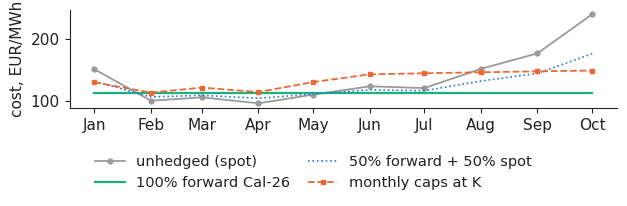

In [9]:
MON = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
fig, ax = plt.subplots(figsize=(6.4, 2.1))
xm = STRAT.index + pd.Timedelta(days=14)
ax.plot(xm, STRAT['spot'], marker='o', ms=3.5, color='#9a9a9a', lw=1.3, label='unhedged (spot)')
ax.plot(xm, STRAT['fwd'], color=PAL['HU'], lw=1.6, label=f'100% forward Cal-{str(END.year)[2:]}')
ax.plot(xm, STRAT['half'], color=PAL['RO'], lw=1.2, ls=':', label='50% forward + 50% spot')
ax.plot(xm, STRAT['cap'], color=PAL['DE_LU'], lw=1.3, ls='--', marker='s', ms=3, label='monthly caps at K')
ax.set_ylabel('cost, EUR/MWh')
ax.set_xticks(xm)
ax.set_xticklabels([MON[m.month - 1] for m in STRAT.index])
legend_bottom(fig, ncol=2)
save_chart(fig, 'case2026')